Please upload your housing dataset CSV from your device:


Saving kc_house_data.csv to kc_house_data (2).csv

✅ AI Output (R2 Score): 0.5089



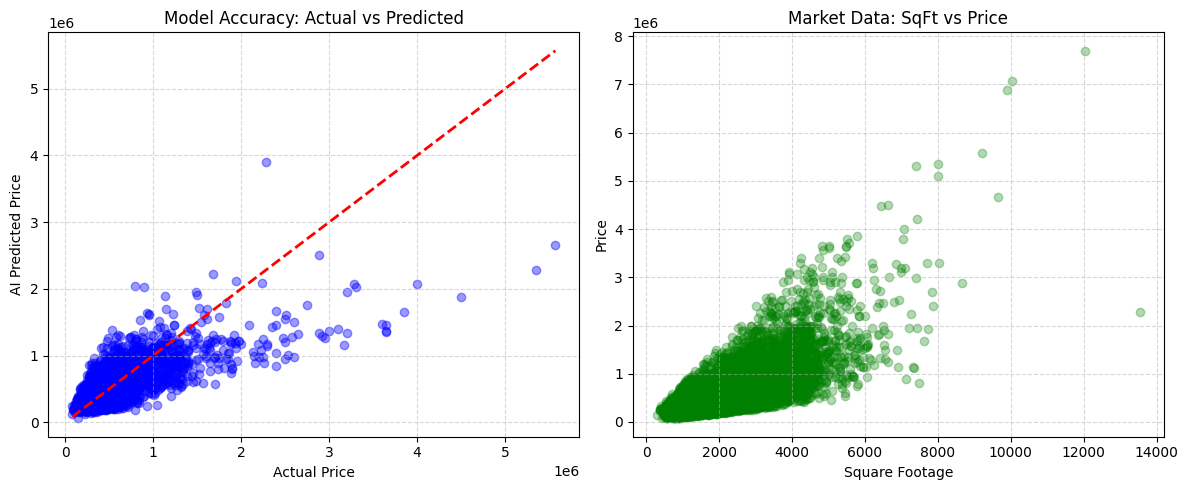


--- ENTER VARIABLES FOR PRICE PREDICTION ---
Enter Square Footage: 8000
Enter Number of Bedrooms: 5
Enter Number of Bathrooms: 3

>> AI Predicted Price: $2,267,076.33


In [ ]:
import pandas as pd
import io
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. IMPORT FILE FROM YOUR DEVICE
print("Please upload your housing dataset CSV from your device:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# 2. LINEAR REGRESSION MODEL
X = df[['sqft_living', 'bedrooms', 'bathrooms']].fillna(0)
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

# 3. AI OUTPUT IN TERMS OF R2
predictions = model.predict(X_test)
r2 = r2_score(y_test, predictions)
print(f"\n AI Output (R2 Score): {r2:.4f}\n")

# 4. CHARTS AND GRAPHS
plt.figure(figsize=(12, 5))

# Chart 1: AI Accuracy (Actual vs Predicted)
plt.subplot(1, 2, 1)
plt.scatter(y_test, predictions, alpha=0.4, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', lw=2)
plt.xlabel("Actual Price")
plt.ylabel("AI Predicted Price")
plt.title("Model Accuracy: Actual vs Predicted")
plt.grid(True, linestyle='--', alpha=0.5)

# Chart 2: Square Footage Impact on Price
plt.subplot(1, 2, 2)
plt.scatter(df['sqft_living'], df['price'], alpha=0.3, color='green')
plt.xlabel("Square Footage")
plt.ylabel("Price")
plt.title("Market Data: SqFt vs Price")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 5. INPUT VARIABLES TO GET OUTPUT OF PREDICTED PRICES
print("\n ENTER VARIABLES FOR PRICE PREDICTION ")
sqft = float(input("Enter Square Footage: "))
beds = float(input("Enter Number of Bedrooms: "))
baths = float(input("Enter Number of Bathrooms: "))

new_house = pd.DataFrame({'sqft_living': [sqft], 'bedrooms': [beds], 'bathrooms': [baths]})
predicted_price = model.predict(new_house)[0]

print(f"\n>> AI Predicted Price: ${predicted_price:,.2f}")